Lab 8 — Naive Bayes: Glass Identification

Names: Joonsuh Kim, William Roberts

Dataset: UCI Glass Identification
Source: https://archive.ics.uci.edu/dataset/42/glass+identification

Algorithm: Gaussian Naive Bayes (GaussianNB)

Question:
Can we identify the type of glass using its chemical composition
and refractive index?

Dataset description:
The dataset contains 214 glass samples and nine numerical
features. Six glass types are represented in the data.

Input features:
RI, Na, Mg, Al, Si, K, Ca, Ba, and Fe.

Target:
Type — the glass category.

The ID column is a sample identifier and is not used for prediction.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# The original file has no column names
columns = [
    "ID", "RI", "Na", "Mg", "Al", "Si",
    "K", "Ca", "Ba", "Fe", "Type"
]

# Read the comma-separated data and assign column names
df = pd.read_csv(
    "glass.data",
    header=None,
    names=columns
)

display(df.head())

print("Rows and columns:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSamples in each glass type:")
print(df["Type"].value_counts().sort_index())

,ID,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Rows and columns: (214, 11)

Missing values:
ID      0
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Samples in each glass type:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


Rows and columns: (214, 11)

Data preparation

The dataset has no missing values. The glass types have different
numbers of samples, so the classes are not balanced.

I remove ID from the input features because it only identifies
each sample. I also remove Type from the inputs because it is
the answer the model must predict.

I split the data into 80% training data and 20% test data.
Stratification keeps the class proportions approximately similar
in both sets.

In [ ]:
# Exclude the identifier and target from the inputs
X = df.drop(["ID", "Type"], axis=1)
y = df["Type"]

# Keep approximately similar class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 171
Test samples: 43


Training samples: 171
Test samples: 43

Model selection

I use Gaussian Naive Bayes because the input features are
numerical measurements, following the instructor's Iris example.

The model estimates a separate normal distribution for each
feature within each glass type. It assumes the features are
conditionally independent given the glass type.

Unlike KNN, GaussianNB does not classify samples using distances.
I use the measurements in their original units in this example.

In [ ]:
# Create a Naive Bayes model for numerical measurements
model = GaussianNB()

# Learn from the training measurements and known glass types
model.fit(X_train, y_train)

# Predict the types of the test samples
y_pred = model.predict(X_test)

print("Training and prediction completed.")

Training and prediction completed.


Evaluating the results

I evaluate the model using test accuracy, a classification report,
and a confusion matrix.

Since the glass types have different sample counts, accuracy
alone does not show how well the model recognizes every type.
The report and confusion matrix help identify which types are
recognized and which are confused with other types.

In the confusion matrix, rows show actual types and columns show
predicted types.

Test accuracy: 51.16%
Correct predictions: 22 out of 43

Classification report:
              precision    recall  f1-score   support

           1       0.50      0.86      0.63        14
           2       0.40      0.13      0.20        15
           3       0.00      0.00      0.00         3
           5       0.50      0.33      0.40         3
           6       0.50      1.00      0.67         2
           7       0.83      0.83      0.83         6

    accuracy                           0.51        43
   macro avg       0.46      0.53      0.46        43
weighted avg       0.48      0.51      0.45        43



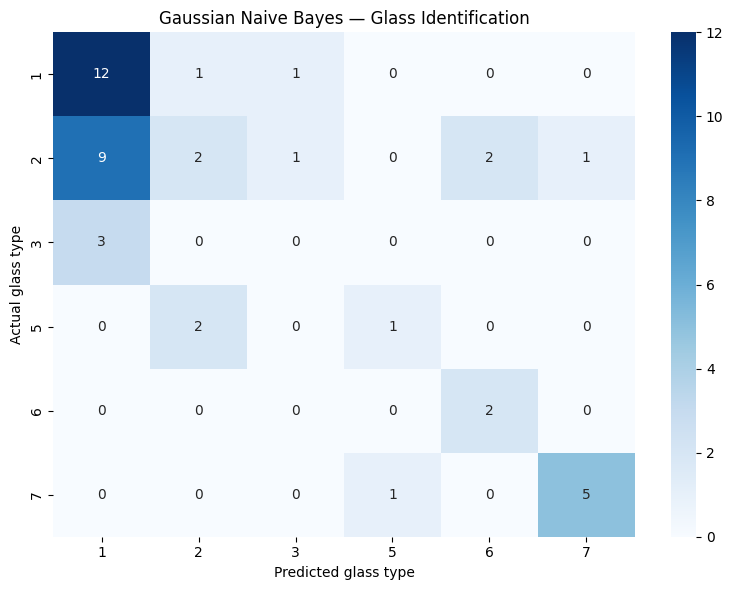

In [ ]:
# Calculate the percentage and number of correct predictions
accuracy = accuracy_score(y_test, y_pred)
correct = (y_test.to_numpy() == y_pred).sum()

print(f"Test accuracy: {accuracy:.2%}")
print(f"Correct predictions: {correct} out of {len(y_test)}")

# Report performance for each glass type
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=model.classes_,
    zero_division=0
))

# Compare actual and predicted types
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted glass type")
plt.ylabel("Actual glass type")
plt.title("Gaussian Naive Bayes — Glass Identification")
plt.tight_layout()
plt.show()

Test accuracy: 51.16%
Correct predictions: 22 out of 43

Summary

I used Gaussian Naive Bayes to identify glass types from nine
measurements of chemical composition and refractive index.
I removed the ID column and checked for missing values.
I trained the model on 171 samples and tested it on 43 samples.

The model correctly classified 22 of the 43 test samples,
giving an accuracy of 51.2%. It correctly identified 12 of
14 type 1 samples and 5 of 6 type 7 samples. However, it
identified only 2 of 15 type 2 samples and none of the three
type 3 samples. Nine type 2 samples were incorrectly predicted
as type 1.

These results show that the model recognized some glass types
better than others. Although the measurements provided useful
information, this model did not reliably distinguish all six
types. Its predictions would need further checking before
being used to identify unknown glass.

The dataset is small, the class sizes are unequal, and the
results are based on one train-test split. For example, both
type 6 test samples were classified correctly, but two samples
are not enough to show that the model always recognizes that type.